# KI-TWPA serpentine (NY CREATES geometry via twpa-sim), rebuilt in the Quantcore PDK

**What it is.** A kinetic-inductance travelling-wave parametric amplifier: a long artificial transmission line of a
thin superconducting film whose inductance depends on the current, L(I) = L0 (1 + I²/I*²). A DC bias plus a pump
give three-wave mixing (pump → signal + idler) along the line; periodic *loaded* cells (shorter capacitive fingers)
open a stop band that keeps the pump's third harmonic from propagating and sets the phase matching (Eom et al.,
Nat. Phys. 8, 623 (2012); Malnou et al., PRX Quantum 2, 010302 (2021)).

**Source.** twpa-sim (S. Mandal, MIT) `src/twpa/layout/kit.py` + `KITLayout`, a parameterised port of the
NY CREATES research layout (`kit_nycreates_research.json`): NbN 60 nm, 20 pH/□; a 0.58 µm spine with 0.5 µm gaps;
0.5 µm fingers in 0.25 µm slots, 75.5 µm long (27.5 µm on the loaded cells); supercells of 24 + 6 + 24 cells at a
1.5 µm pitch; 16 rows × 55 supercells joined by U-turns of radius 154 µm (3 supercells each) — 49 950 cells, the
electrical `v2-standard` line (925 supercells; L 53.8 pH, C 22.3 / 8.4 fF per cell). Read-only clone
`build/external/twpa-sim` (rev 05abc83), never run.

| | source | Quantcore rebuild (why) |
|---|---|---|
| geometry | 16 × 55 serpentine, radial turn fingers, turn spine widened to match sheet squares | the same (`KiTwpaSerpentine`: twpa-sim's primitives re-drawn as a negative mask) |
| film | **NbN 60 nm, 20 pH/□** | **PDK Nb 200 nm, 0.116 pH/□**: ≈ 170× less kinetic inductance |
| line impedance | ≈ 50 Ω (L dominated by kinetic inductance) | **≈ 6 Ω on Nb** and weakly nonlinear (kinetic share ≈ 30 %): flagged; the NbN case is shown in the analysis only, via a `KineticInductance(sheet_inductance_pH_sq=20)` override (no PDK change) |
| grounds | two separate ground combs (package grounding) | one chip ground plane |
| launches | 103 µm bump-landing bays | tapers from the spine to the 10/6 µm chip CPW, Quantcore `BondPad`s 100 µm from the edge |
| chip | 5 × 5 mm | 7.5 × 7.5 mm PDK die; both launches on the west side (even row count, as the source), so the content sits off-centre in x |

## 1 · Setup and the PDK

In [2]:
import os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "amplifiers"))
from _common import *
from _amplifiers import pdk_facts_md, plot, show_md, table_md
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import KineticInductance, get_pdk
from quantcore_circuits.analysis import amplifiers as amp
from quantcore_circuits.layouts.others.amplifiers import KiTwpaSerpentine

LIVE = os.environ.get("QCC_LIVE", "1") == "1"
RUN_FEM = False
FULL_SIZE = False        # True: draw the 16-row reference (49 950 cells; the build takes minutes, see the note in 3)
OUT = Path("examples/designs/amplifiers")
PDK = get_pdk()
NBN = replace(PDK, kinetic=KineticInductance(sheet_inductance_pH_sq=20.0))   # the source film, analysis only
show_md(pdk_facts_md(PDK))

| PDK | value |
|---|---|
| substrate | sapphire 650 µm, εr 10.25 |
| film | Nb 200 nm, λ_L 90 nm → L_s 0.116 pH/□ (kinetic, in every CPW / wire formula) |
| junction rule | Nb/AlOx/Nb trilayer, Δ 1.4 meV, J_c 0.163 µA/µm², R_n window 40–50 kΩ, fingers 0.1–2 µm |
| frame | die 7.5 × 7.5 mm standard, margin 100 µm, marker areas 500 µm, brand QCT |
| pad rule | outer etch 100 µm (one dicing-marker width) from the die edge (`edge="auto"`) |
| cheese | PDK band 3 rows of 5 µm squares, 20 µm gap, around the 3/0 keep-outs (unless the original has its own) |
| 3/0 keep-out | routes + 10 µm, components + 24 µm |

## 2 · The die and frame

In [3]:
W = H = 7500
d = Designer("ki_twpa_serpentine", box=(0, 0, W, H), chip={"name_chip": "KITWPA"}, live=LIVE)

## 3 · Pads (the 100 µm rule)
Input and output `BondPad`s on the west edge at the heights of the first and last rows (`edge="auto"`).

**Size.** The saved design draws 4 rows of the full 55-supercell length (12 474 cells); `FULL_SIZE = True` draws
the 16-row reference (49 950 cells). The full line merges into two etch polygons of ≈ 0.8 M vertices and the
build's 3/0 step grows the whole etch by 5 µm (≈ 2 min); the analysis below always uses the 49 950-cell line.

In [4]:
N_ROWS = 16 if FULL_SIZE else 4
KIT = dict(rows=N_ROWS, periods_per_row=55)
REF = dict(rows=16, periods_per_row=55)   # the source line
XK, YK = 4000, 3750                                # serpentine centre (rows along x)
with d.batch():
    d.add("P_IN", "BondPad", at=(400, YK + (N_ROWS - 1) * 154), rot=-90, edge="auto")
    d.add("P_OUT", "BondPad", at=(400, YK - (N_ROWS - 1) * 154), rot=-90, edge="auto")

## 4 · Components
`KIT` (`KiTwpaSerpentine`): the rows are arrays of one supercell etch (spine gaps + finger slots), the U-turns
twpa-sim's constant-width radial fingers with the smooth-step widened spine (the sheet-square match is solved per
build, `brentq`); the launches taper the 0.58 µm spine to the 10/6 µm CPW over 88 µm and run 155 µm to the ports.

In [5]:
t0 = time.time()
with d.batch():
    d.add("KIT", "KiTwpaSerpentine", at=(XK, YK), **KIT)
LAD_NB = KiTwpaSerpentine.qcc_ladder(REF, PDK)
LAD_NBN = KiTwpaSerpentine.qcc_ladder(REF, NBN)
DRAWN = KiTwpaSerpentine.qcc_ladder(KIT, PDK)
SRC = {"L_cell_pH": 20 * (1.5 / 0.58) * 1.04, "C_cell_fF": 22.32, "C_loaded_fF": 8.38}   # twpa-sim v2 preset
show_md(table_md(["per cell", "PDK Nb (drawn)", "NbN 20 pH/□ (override)", "twpa-sim v2 (calibrated)"], [
    ["sheet L_s (pH/□)", LAD_NB["sheet_pH_sq"], LAD_NBN["sheet_pH_sq"], 20],
    ["L geometric (pH)", LAD_NB["L_geo_pH"], LAD_NBN["L_geo_pH"], None],
    ["L kinetic (pH)", LAD_NB["L_k_pH"], LAD_NBN["L_k_pH"], None],
    ["L total (pH)", LAD_NB["L_cell_pH"], LAD_NBN["L_cell_pH"], SRC["L_cell_pH"]],
    ["kinetic share α_k", LAD_NB["alpha_k"], LAD_NBN["alpha_k"], 1.0],
    ["C unloaded / loaded (fF)", f"{LAD_NB['C_cell_fF']:.1f} / {LAD_NB['C_loaded_fF']:.1f}",
     f"{LAD_NBN['C_cell_fF']:.1f} / {LAD_NBN['C_loaded_fF']:.1f}", "22.3 / 8.4"],
    ["Z = √(L/C) (Ω)", LAD_NB["Z_cell_ohm"], LAD_NBN["Z_cell_ohm"],
     np.sqrt(SRC["L_cell_pH"] * 1e-12 / (SRC["C_cell_fF"] * 1e-15))],
    ["cells / supercells (reference)", f"{LAD_NB['cells']} / {LAD_NB['supercells']}", "same", "49 950 / 925"]])
    + "\n\n" + f"Drawn on this die: {DRAWN['cells']} cells ({DRAWN['supercells']} supercells, {DRAWN['length_um'] / 1e3:.1f} mm of line).")

| per cell | PDK Nb (drawn) | NbN 20 pH/□ (override) | twpa-sim v2 (calibrated) |
|---|---|---|---|
| sheet L_s (pH/□) | 0.1158 | 20 | 20 |
| L geometric (pH) | 0.7063 | 0.7063 | – |
| L kinetic (pH) | 0.2994 | 51.72 | – |
| L total (pH) | 1.006 | 52.43 | 53.79 |
| kinetic share α_k | 0.2977 | 0.9865 | 1 |
| C unloaded / loaded (fF) | 23.6 / 8.6 | 23.6 / 8.6 | 22.3 / 8.4 |
| Z = √(L/C) (Ω) | 6.531 | 47.15 | 49.09 |
| cells / supercells (reference) | 49950 / 925 | same | 49 950 / 925 |

Drawn on this die: 12366 cells (229 supercells, 18.5 mm of line).

## 5 · Routes
Short 50 Ω feeds from the pads to the two launches.

In [6]:
with d.batch():
    d.route("L_IN", "P_IN.a", "KIT.a")
    d.route("L_OUT", "P_OUT.a", "KIT.b")
d.sim_group("launch", ["KIT"], margin_um=40, analyses=["q3d_cmatrix"])
if not LIVE:
    d.show()
DESIGN = d.save(OUT / "ki_twpa_serpentine.json")
print(d, "→", DESIGN, f"(layout built in {time.time() - t0:.1f} s)")

<Designer ki_twpa_serpentine: 3 instances, 2 routes, live=False> → examples\designs\amplifiers\ki_twpa_serpentine.json (layout built in 4.2 s)


## 6 · DRC
No junctions; the content is off-centre in x (both launches on the west side: an even number of rows).

In [7]:
print(d.drc())
show_md(pdk_report(d))

DRC clean


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (-471, +0) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 7 · Netlist and LOM
`KiTwpaSerpentine`'s model is one conductor between its ports (both pads: a wire, two 50 Ω ports); the ladder that
describes the line — L and C per cell, the loaded cells — comes from `KiTwpaSerpentine.qcc_ladder`, with the
film's L_s from the PDK (`pdk.kinetic`) or an override.

In [8]:
lb = d.lom()
show_netlist(lb)

**2 nodes · 2 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `KIT.line` | `P_IN.pad`, `P_OUT.pad`, `KIT.line` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P_IN` | R | `KIT.line` – `gnd` | 50 Ω |
| `Port_P_OUT` | R | `KIT.line` – `gnd` | 50 Ω |

**Unconnected ports:** none

**Builder notes:**

- KIT: KI-TWPA ladder of 12366 cells, L 1.01 pH/cell (kinetic 29.8% at 0.116 pH/□), C 23.6 fF/cell, Z ≈ 7 Ω (analysis.amplifiers for dispersion and gain)

## 8 · LOM simulation: dispersion, stop band, gain
**(a) Linear response** of the supercell (24 + 6 + 24 cells, `analysis.amplifiers.ki_supercell`: two fingers per
cell with their stub inductance, L_s × squares / 3): Bloch phase per cell and attenuation, for the PDK Nb drawing,
the same drawing on NbN, and twpa-sim's calibrated v2 cell.

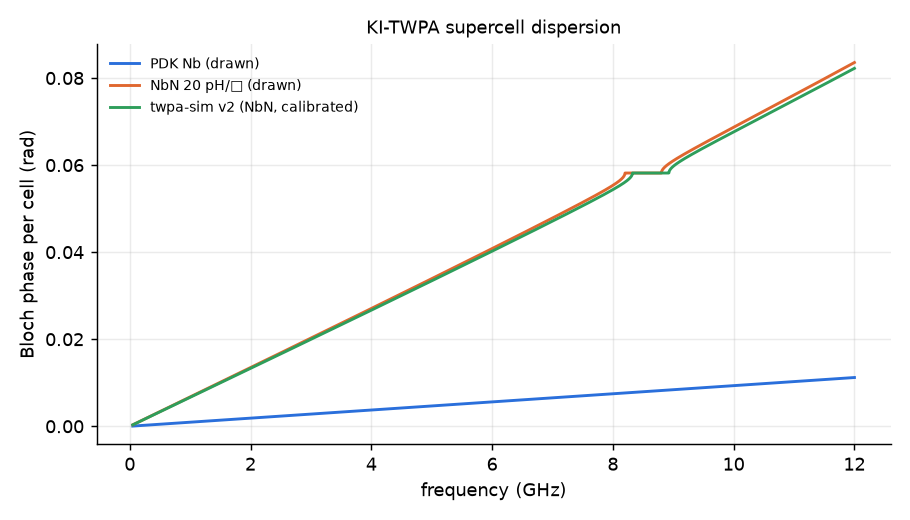

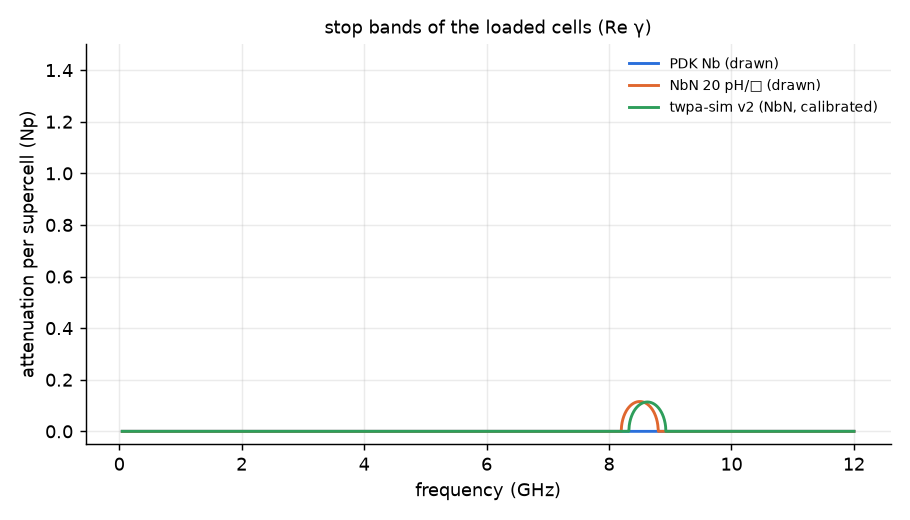

WindowsPath('examples/designs/amplifiers/ki_twpa_serpentine_stopband.png')

In [9]:
f = np.linspace(0.05e9, 12e9, 4000)
def unit(lad=None, src=False):
    if src:
        lu, cu, cl = SRC["L_cell_pH"] * 1e-12, SRC["C_cell_fF"] * 1e-15, SRC["C_loaded_fF"] * 1e-15
        su, sl = 20e-12 * (75.5 / 0.5) / 3, 20e-12 * (27.5 / 0.5) / 3
    else:
        lu, cu, cl = lad["L_cell_pH"] * 1e-12, lad["C_cell_fF"] * 1e-15, lad["C_loaded_fF"] * 1e-15
        su, sl = lad["sheet_pH_sq"] * 1e-12 * (75.5 / 0.5) / 3, lad["sheet_pH_sq"] * 1e-12 * (27.5 / 0.5) / 3
    return amp.ki_supercell(f, lu, cu, cl, 48, 6, su, sl)
CASES = {"PDK Nb (drawn)": unit(LAD_NB), "NbN 20 pH/□ (drawn)": unit(LAD_NBN), "twpa-sim v2 (NbN, calibrated)":
         unit(src=True)}
gam = {k: amp.bloch(u) / 54 for k, u in CASES.items()}
plot(OUT / "ki_twpa_serpentine_dispersion.png", [(f / 1e9, amp.unwrap_bloch(54 * g.imag) / 54, k) for k, g in gam.items()],
     "frequency (GHz)", "Bloch phase per cell (rad)", "KI-TWPA supercell dispersion")
plot(OUT / "ki_twpa_serpentine_stopband.png", [(f / 1e9, 54 * g.real, k) for k, g in gam.items()],
     "frequency (GHz)", "attenuation per supercell (Np)", "stop bands of the loaded cells (Re γ)", ylim=(-0.05, 1.5))

**(b) 3WM gain** (DC-biased, `analysis.amplifiers.cme_gain(mode="3wm")`, twpa-sim's `v2` bias: I* 1 mA,
I_dc 0.2 mA, I_p 16.7 µA peak, Kerr factor 2), the pump chosen as twpa-sim does: just above the first stop band,
where k_p − k_s − k_i + ξI_p²/8 (k_p − 2k_s − 2k_i) is smallest (signal and idler 1 GHz apart). On Nb only the
kinetic share α_k of the inductance is current-dependent: ε and ξ scale by α_k (I* kept at 1 mA: the Nb line's
I* is not known) — and the Nb line's loaded-cell stop band lies far above the band (its L per cell is ≈ 50×
smaller), so there is no phase-matched pump in range: the drawn Nb device does not amplify as designed.

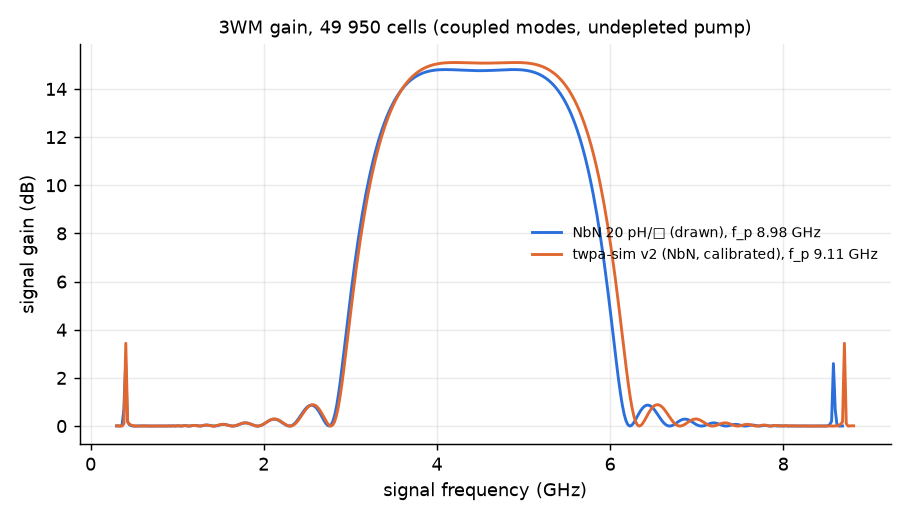

| line | pump (GHz) | G at f_p/2 (dB) | max G (dB) |
|---|---|---|---|
| PDK Nb (drawn) | no stop band below 12 GHz | – | – |
| NbN 20 pH/□ (drawn) | 8.985 | 14.76 | 14.8 |
| twpa-sim v2 (NbN, calibrated) | 9.113 | 15.07 | 15.1 |

In [10]:
I_STAR, I_DC, I_P = 1e-3, 0.2e-3, 1e-3 / 60
cells = LAD_NB["cells"]

def gain_curve(g, alpha_k):
    eps, xi = amp.ki_nonlinearity(I_STAR, I_DC, alpha_k, kerr_factor=2.0)
    k = amp.unwrap_bloch(g.imag * 54) / 54     # unfold the supercell phase past its Bragg stop bands
    stop = np.where(g.real * 54 > 0.05)[0]
    if not len(stop):  # no stop band in range (the Nb line: its loaded-cell band is far above 12 GHz)
        return None, None, None
    edge = f[stop[0] + np.argmax(np.diff(stop) > 1)] if np.any(np.diff(stop) > 1) else f[stop[-1]]
    cand = f[(f > edge + 2e6) & (f < edge + 1.2e9) & (f < f[-1] - 1.3e9)]
    kf = lambda x: np.interp(x, f, k)
    mis = kf(cand) - kf((cand - 1e9) / 2) - kf((cand + 1e9) / 2) + xi * I_P**2 / 8 * (
        kf(cand) - 2 * kf((cand - 1e9) / 2) - 2 * kf((cand + 1e9) / 2))
    fp = float(cand[np.argmin(np.abs(mis))])
    fs = np.linspace(0.3e9, fp - 0.3e9, 400)
    gg, _, _ = amp.cme_gain(kf(fs), kf(fp - fs), kf(fp), cells, I_P, xi=xi, eps=eps, mode="3wm")
    return fp, fs, amp.db(gg)

curves, rows = [], []
for (label, g), ak in zip(gam.items(), (LAD_NB["alpha_k"], LAD_NBN["alpha_k"], 1.0)):
    fp, fs, gdb = gain_curve(g, ak)
    if fp is None:
        rows.append([label, "no stop band below 12 GHz", None, None])
        continue
    curves.append((fs / 1e9, gdb, f"{label}, f_p {fp / 1e9:.2f} GHz"))
    rows.append([label, fp / 1e9, float(np.interp(fp / 2, fs, gdb)), float(gdb.max())])
plot(OUT / "ki_twpa_serpentine_gain.png", curves, "signal frequency (GHz)", "signal gain (dB)",
     "3WM gain, 49 950 cells (coupled modes, undepleted pump)")
show_md(table_md(["line", "pump (GHz)", "G at f_p/2 (dB)", "max G (dB)"], rows))

## 9 · FEM: send the jobs
A Q3D C-matrix job of the whole line is a 50 k-finger mesh; the sim group is defined so the export exists, but a
useful extraction is one supercell (C per finger) — run it on a short `KiTwpaSerpentine(rows=2, periods_per_row=1)`
in a separate design. Export only.

In [11]:
t0 = time.time()
jobs = export_sims(DESIGN, ["launch"])
display(Markdown(jobs_md(jobs) + f"\n\n(exported in {time.time() - t0:.0f} s)"))
if RUN_FEM:
    from quantcore_circuits.sim_tools import solve_job
    solve_job(jobs["launch"][0])

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| launch | `build/jobs/ki_twpa_serpentine_launch_q3d_cmatrix` | 1 · edge · `L_IN`<br>2 · edge · `L_OUT` | `L_IN` |

(exported in 128 s)

## 10 · Bring it back

In [12]:
job = jobs["launch"][0]
show_md("C-matrix found: replace C per cell in section 8 by the extracted value" if (Path(job) / "results" /
        "results.json").exists() else f"No results in `{job}` yet: C per cell is the analytic CPW estimate.")

No results in `build\jobs\ki_twpa_serpentine_launch_q3d_cmatrix` yet: C per cell is the analytic CPW estimate.

## 10b · The kinetic film is the knob
On the PDK film the line is ≈ 6 Ω; what sheet inductance would bring this geometry to 50 Ω? (The film's L_s is a
PDK parameter — `KineticInductance(sheet_inductance_pH_sq=…)`; a thinner or a different film, e.g. NbN / NbTiN.)

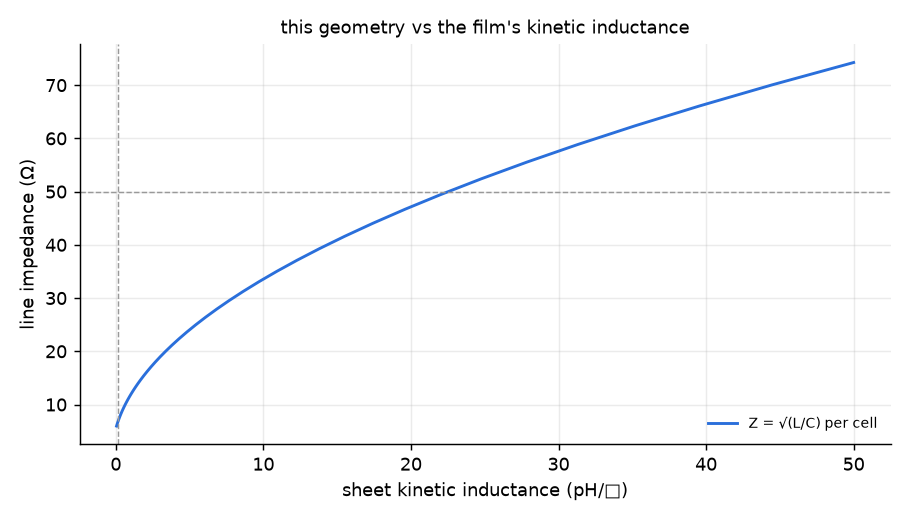

50 Ω at L_s ≈ 22.5 pH/□ (PDK Nb: 0.116 pH/□).

In [13]:
ls = np.geomspace(0.05, 50, 60)
z = [KiTwpaSerpentine.qcc_ladder(REF, replace(PDK, kinetic=KineticInductance(sheet_inductance_pH_sq=float(x))))[
     "Z_cell_ohm"] for x in ls]
plot(OUT / "ki_twpa_serpentine_impedance.png", [(ls, z, "Z = √(L/C) per cell")], "sheet kinetic inductance (pH/□)",
     "line impedance (Ω)", "this geometry vs the film's kinetic inductance", hline=50,
     vline=LAD_NB["sheet_pH_sq"])
show_md(f"50 Ω at L_s ≈ {float(np.interp(50, z, ls)):.1f} pH/□ (PDK Nb: {LAD_NB['sheet_pH_sq']:.3f} pH/□).")

## 11 · Iterate: fewer, shorter fingers
One property: finger length 75.5 → 25 µm (and loaded 27.5 → 9 µm), C per cell ÷ 3: on Nb the line gets closer
to 50 Ω, but the stop band moves up and the dispersion changes; the kinetic share stays small.

In [14]:
short = dict(REF, finger_length=25, loaded_finger_length=9)
lad_s = KiTwpaSerpentine.qcc_ladder(short, PDK)
show_md(table_md(["fingers (µm)", "C unloaded (fF)", "Z (Ω)", "α_k"], [
    ["75.5 / 27.5", LAD_NB["C_cell_fF"], LAD_NB["Z_cell_ohm"], LAD_NB["alpha_k"]],
    ["25 / 9", lad_s["C_cell_fF"], lad_s["Z_cell_ohm"], lad_s["alpha_k"]]]))

| fingers (µm) | C unloaded (fF) | Z (Ω) | α_k |
|---|---|---|---|
| 75.5 / 27.5 | 23.58 | 6.531 | 0.2977 |
| 25 / 9 | 7.853 | 11.32 | 0.2977 |

## 12 · Build and export
`qcc build examples/designs/amplifiers/ki_twpa_serpentine.json`; `qcc mask …` (the fab export rounds corners: the
0.25 µm slots are below the rounding's 2 µm minimum edge, so they stay sharp).

In [15]:
from quantcore_circuits.layouts.wafers.fab_export import export_fab
if d.result is None:
    d.show()
t0 = time.time()
fab = {}
export_fab(d.result, Path("build") / f"{d.design.name}_fab.oas", report=fab)
show_md(f"cheese: {fab.get('cheese_source')}; written: " + ", ".join(f"{k} {n}" for k, n in fab["written"].items())
        + f" ({time.time() - t0:.0f} s)")

cheese: build; written: M1 3962, M3 3959, CHIP_BOUNDARY 1, MARKERS_DICING 4, MARKERS_ALIGN 36 (41 s)

## 13 · Snapshots
The full die; a U-turn (radial fingers, widened spine); straight cells around a loaded section; a launch taper.

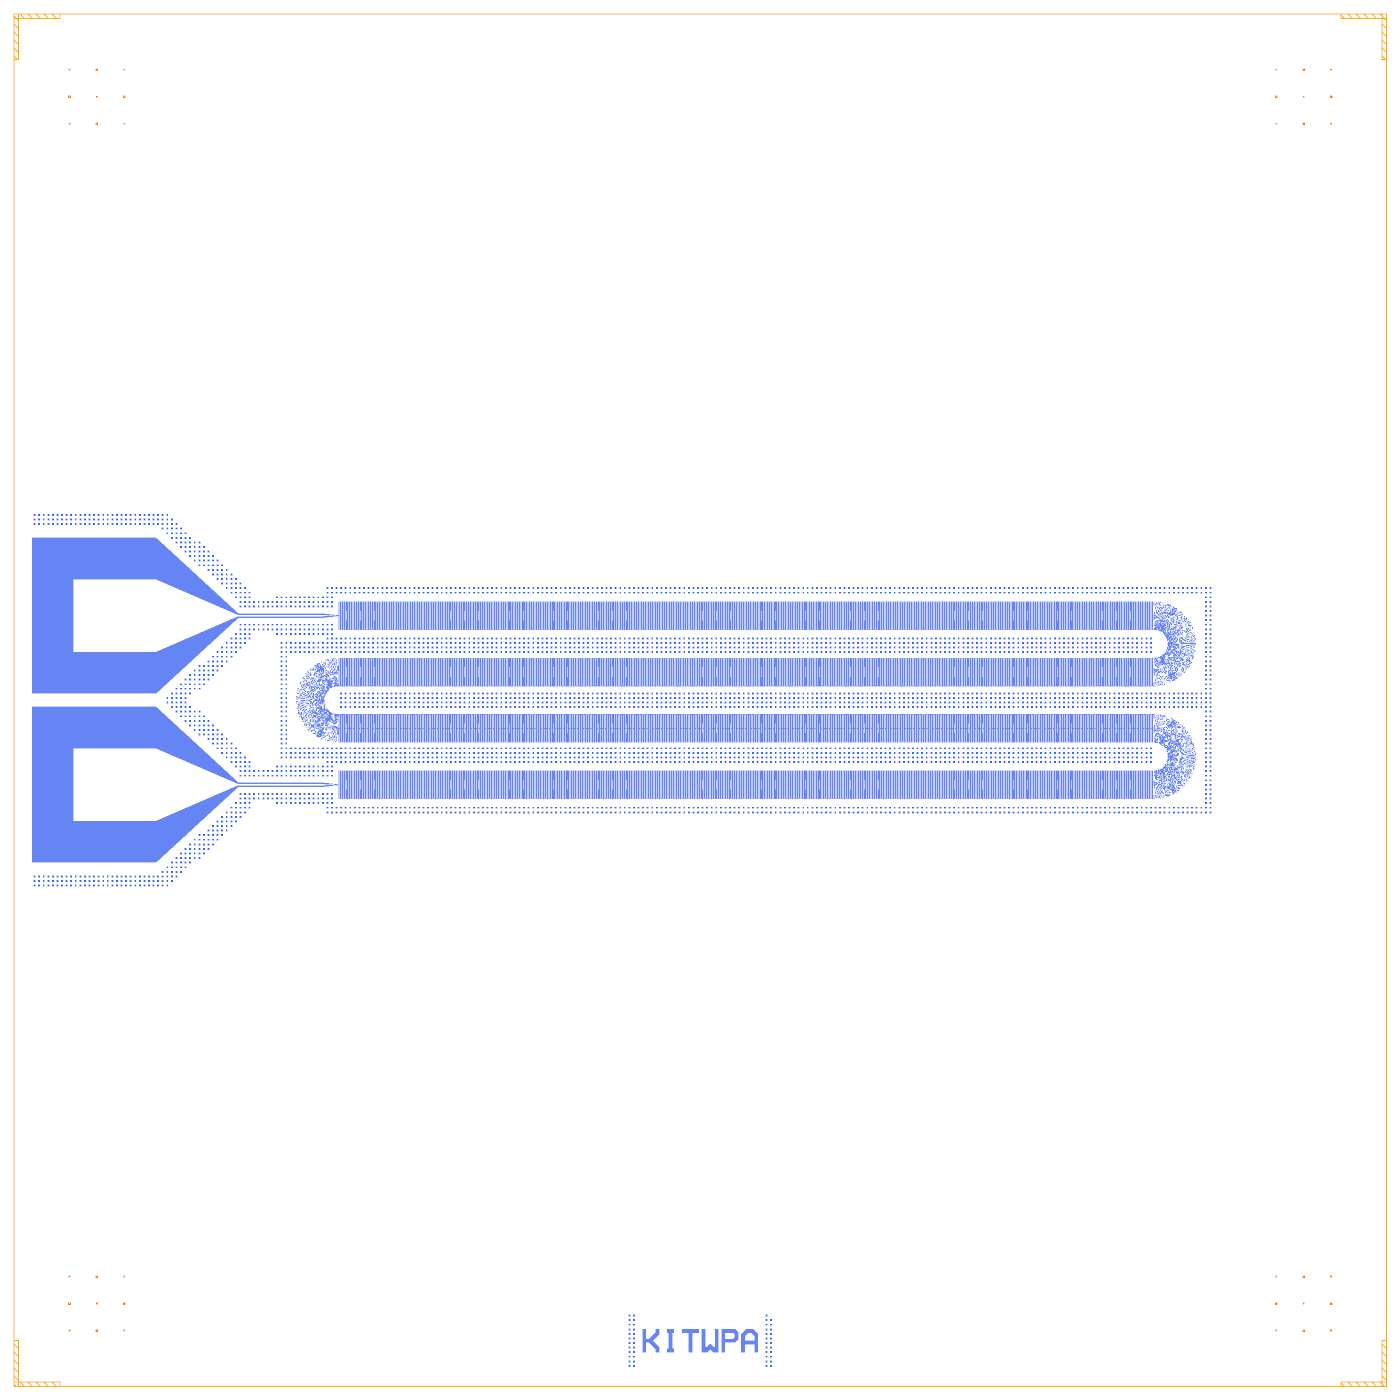

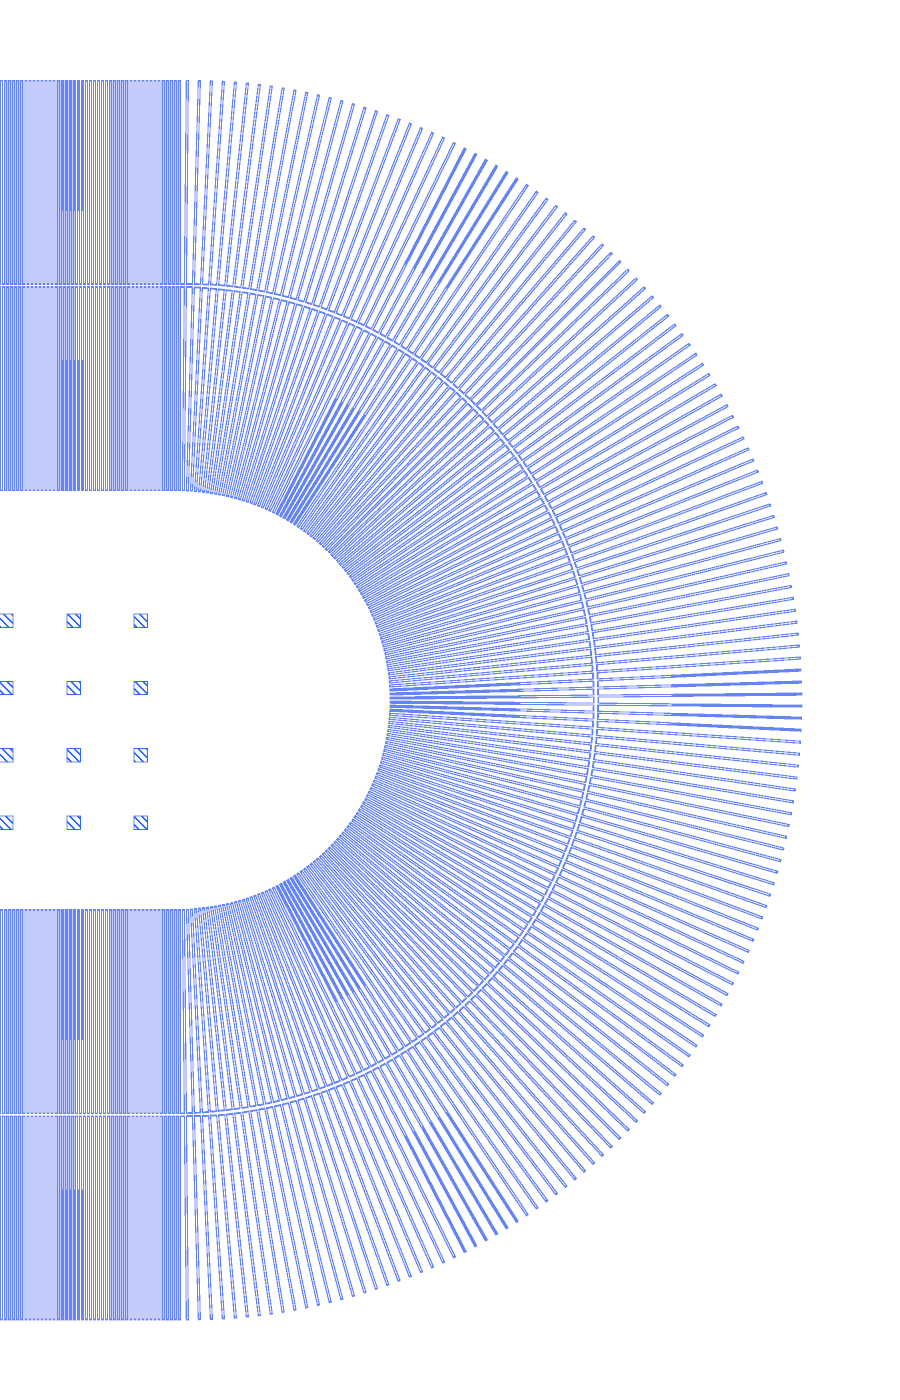

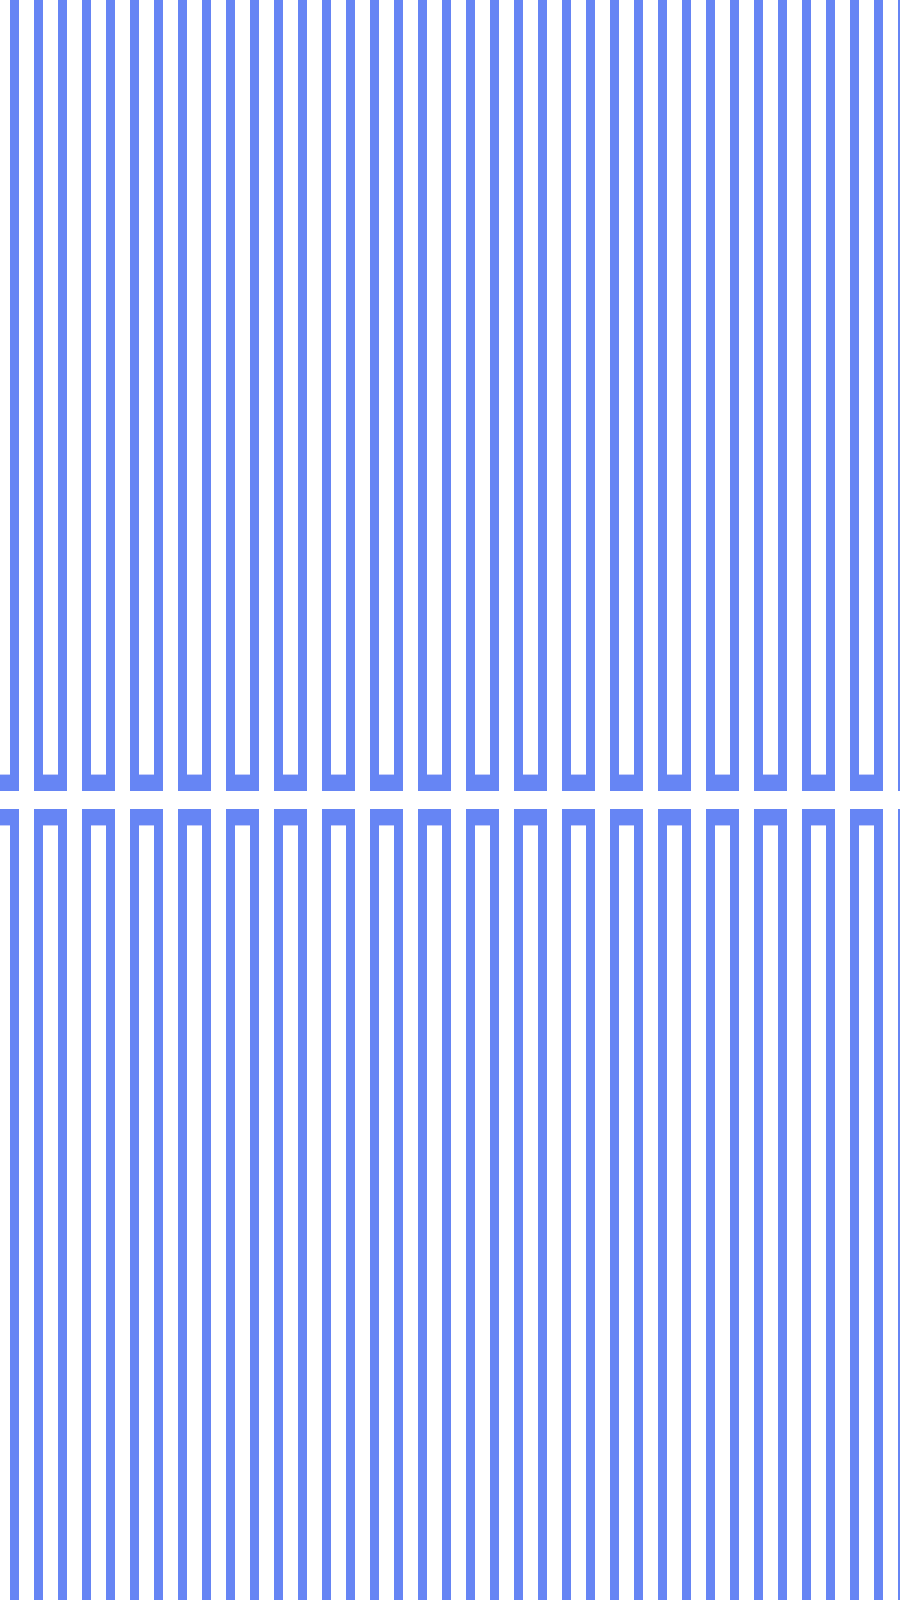

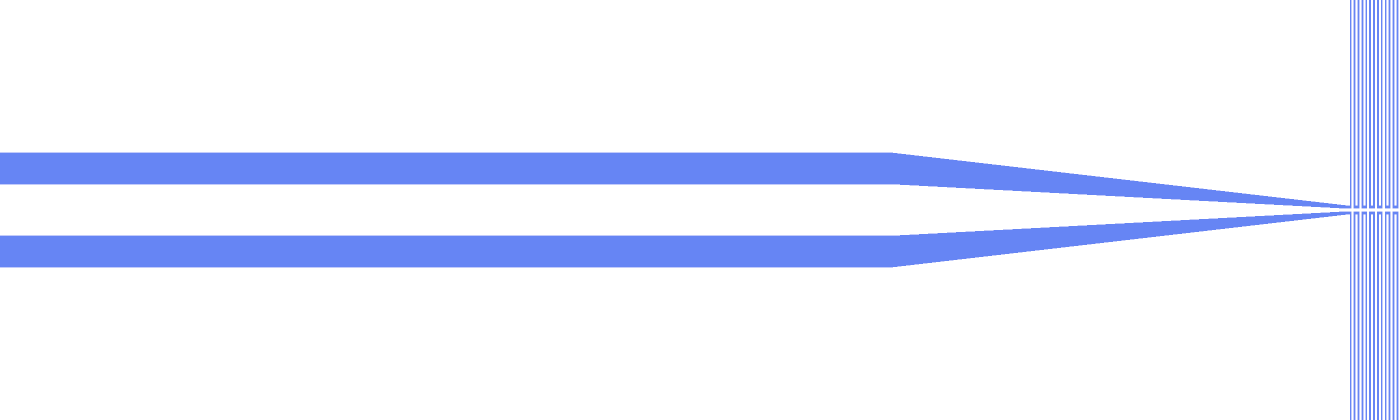

WindowsPath('examples/designs/amplifiers/ki_twpa_serpentine_launch.png')

In [16]:
show_snapshot(d, OUT / "ki_twpa_serpentine.png", size=(1400, 1400))
xr = XK + 55 * 54 * 1.5 / 2
yt = YK + (N_ROWS - 2) * 154                 # centre of the first U-turn
show_snapshot(d, OUT / "ki_twpa_serpentine_turn.png", box=(xr - 60, yt - 260, xr + 260, yt + 260),
              size=(900, 1400), width=360)
xl = XK - 55 * 54 * 1.5 / 2
y0 = YK + (N_ROWS - 1) * 154
show_snapshot(d, OUT / "ki_twpa_serpentine_cells.png", box=(xl + 30, y0 - 25, xl + 55, y0 + 25),
              size=(900, 1600), width=300)
show_snapshot(d, OUT / "ki_twpa_serpentine_launch.png", box=(xl - 260, y0 - 40, xl + 10, y0 + 40),
              size=(1400, 420), width=600)

## 14 · Summary
* **Matches the source:** the twpa-sim / NY CREATES geometry cell for cell (spine, fingers, loaded cells, turns
  with the sheet-square-matched spine; 55-supercell rows). The saved die draws 4 of the 16 rows (`FULL_SIZE`
  draws all: 49 950 cells, twpa-sim's 925-supercell v2 line); the analysis uses the full line.
* **Differs:** the film. On the PDK's 200 nm Nb (0.116 pH/□) the line is ≈ 6 Ω and only ≈ 30 % of its inductance is
  kinetic, so the drawn device is badly mismatched and weakly nonlinear (section 8). The NbN case (20 pH/□, the
  source) is shown through a `KineticInductance` override in the analysis only; a KI-TWPA on this PDK needs a
  high-kinetic-inductance film (or a different geometry). Single chip ground instead of two combs; CPW launches.
* **PDK design warnings:** none (no junctions); the content is off-centre in x by design (both launches west).
* **Not modelled:** TLS loss, pump depletion, the turn's exact impedance (twpa-sim's sheet-square match is an
  approximation), I* of the films.